In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from pacha.L2_processing import radar as l2rad
from pacha.utils import file_utils as futils
from pacha.utils import geospatial as gutils
from pacha.utils import instruments as iutils

In [2]:
l1_rad_dir = '/home/admingosset/WORK/projects/funceme-radar-qpe/data/processed/l1_radar/'
gauges_data_path = '/media/admingosset/T7Shield/data/processed_data/ceara/gauges/v0/gauges_10min_utc.csv'
gauges_metadata_path = '/media/admingosset/T7Shield/data/processed_data/ceara/gauges/v0/gauges_10min_utc_metadata.csv'

gauges = iutils.Gauges(gauges_data_path, gauges_metadata_path)
df_fpaths_l1rad = futils.get_df_dates_filepaths(
    l1_rad_dir, date_char_st=9, date_char_nd=19, date_format='%Y_%m_%d'
)

with xr.open_dataset(df_fpaths_l1rad.iloc[0, 0]) as sample_ds:
    lon0, lat0 = gutils.calc_ds_center(sample_ds)

print(f'Radar center: ({lon0}, {lat0})')

Radar center: (-39.26805152577293, -5.070284552413706)


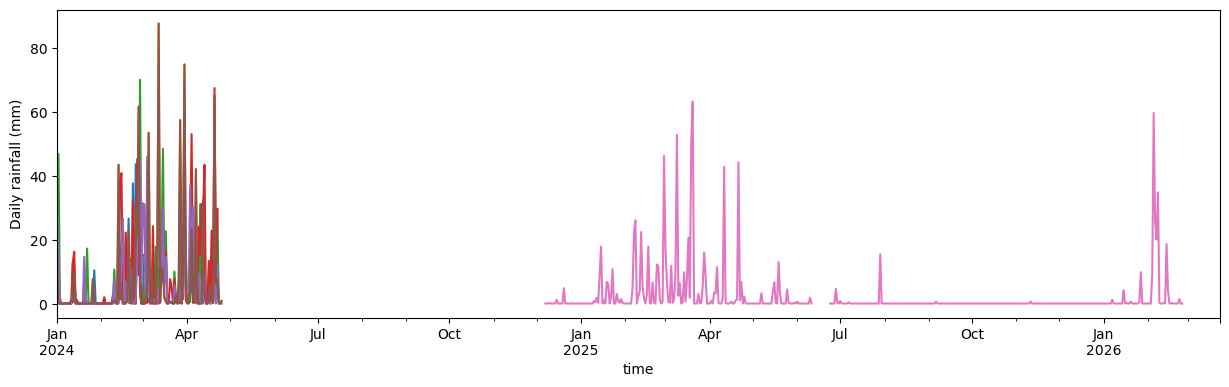

In [3]:
gauges.calc_distance_to_point((lat0, lon0))
close_gauges = gauges.metadata.loc[gauges.metadata.distance_to_point < 120]
close_gauges_data = gauges.data.loc['2024':, close_gauges.index]

min_steps_per_day = int(24 * 6 * 0.8)
df_daily_acc = close_gauges_data.resample('1D').sum(min_count=min_steps_per_day)

df_daily_acc.plot(figsize=(15, 4), legend=False)
plt.ylabel('Daily rainfall (mm)')
plt.show()

In [4]:
def rad_vals_at_stations(ds, stations, gauges, varname='dBZ'):
    dfs = []
    for station in stations:
        point = gauges.get_coords_station(station)
        df = gutils.ds_to_df_at_point(ds, point)[[varname]]
        dfs.append(df.rename(columns={varname: f'{station}_{varname}'}))
    return pd.concat(dfs, axis=1)

In [5]:
dfs = {}

for day in df_fpaths_l1rad.index:
    date = str(day.date())
    df_close = close_gauges_data.loc[date].copy()
    stations = df_close.columns[df_close.sum() > 15].tolist()
    if not stations:
        continue

    df_close = df_close[stations]
    df_close.index = pd.to_datetime(df_close.index)

    with xr.open_dataset(df_fpaths_l1rad.loc[date, 'paths']) as ds:
        df_rad = rad_vals_at_stations(ds, stations, gauges).replace(-100, np.nan)
    df_rad.index = pd.to_datetime(df_rad.index)

    df_gauge = df_close.join(
        l2rad.calc_refl_from_rate(df_close * 6).add_suffix('_ref')
    )
    df_radar = df_rad.join(
        l2rad.calc_rate_from_refl(df_rad).add_suffix('_rate')
    )

    matched = pd.merge_asof(
        df_gauge.sort_index(), df_radar.sort_index(),
        left_index=True, right_index=True,
        direction='nearest', tolerance=pd.Timedelta('5min')
    )

    dfs[date] = {
        station: matched[
            [station, f'{station}_ref', f'{station}_dBZ', f'{station}_dBZ_rate']
        ].set_axis([
            'gauge_measurement_mm', 'ref_from_gauge_dBZ',
            'radar_measurement_dBZ', 'rate_from_rad_mmh'
        ], axis=1)
        for station in stations
    }

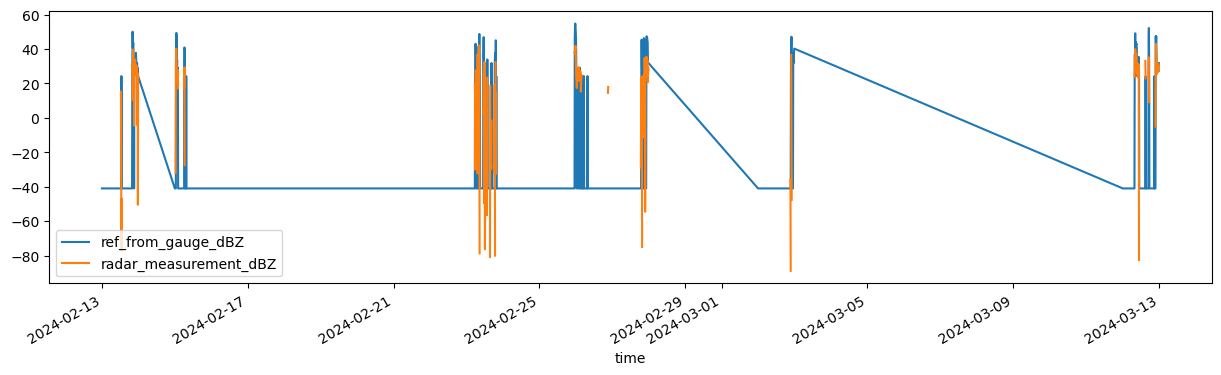

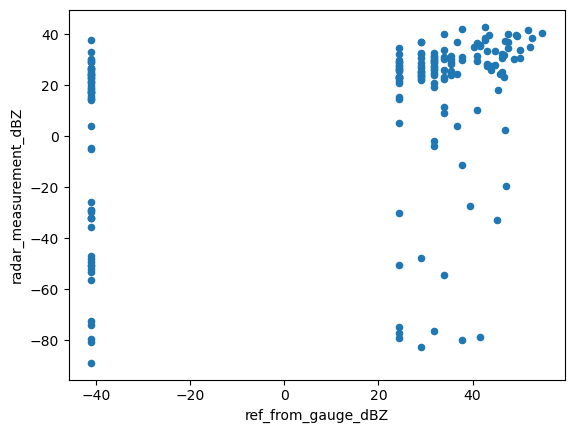

time                         
2024-02-13  rate_from_rad_mmh    0.451324
2024-02-14  rate_from_rad_mmh         NaN
2024-02-15  rate_from_rad_mmh    0.591780
2024-02-16  rate_from_rad_mmh         NaN
2024-02-17  rate_from_rad_mmh         NaN
2024-02-18  rate_from_rad_mmh         NaN
2024-02-19  rate_from_rad_mmh         NaN
2024-02-20  rate_from_rad_mmh         NaN
2024-02-21  rate_from_rad_mmh         NaN
2024-02-22  rate_from_rad_mmh         NaN
2024-02-23  rate_from_rad_mmh    0.114726
2024-02-24  rate_from_rad_mmh         NaN
2024-02-25  rate_from_rad_mmh    0.721802
2024-02-26  rate_from_rad_mmh    0.737519
2024-02-27  rate_from_rad_mmh    0.532219
2024-02-28  rate_from_rad_mmh         NaN
2024-02-29  rate_from_rad_mmh         NaN
2024-03-01  rate_from_rad_mmh         NaN
2024-03-02  rate_from_rad_mmh    0.145428
2024-03-03  rate_from_rad_mmh         NaN
2024-03-04  rate_from_rad_mmh         NaN
2024-03-05  rate_from_rad_mmh         NaN
2024-03-06  rate_from_rad_mmh         NaN
2024

In [6]:
station = 'alto_santo'
df_station = pd.concat(
    [daily[station] for daily in dfs.values() if station in daily]
).sort_index()

df_station[['ref_from_gauge_dBZ', 'radar_measurement_dBZ']].plot(figsize=(15, 4))
plt.show()

df_station.plot.scatter(x='ref_from_gauge_dBZ', y='radar_measurement_dBZ')
plt.show()

daily_corr = df_station.groupby(pd.Grouper(freq='1D')).corr()
daily_corr.loc[(slice(None), 'rate_from_rad_mmh'), 'gauge_measurement_mm']